<a href="https://colab.research.google.com/github/aGalaxyFarAway/Machine-Learning-Final-Project/blob/main/MLPModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Package and Data Imports**

In [ ]:
# --- Loading packages and libraries
import numpy as np
import pandas as pd
import torch
import random
import pickle
import time
import copy
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (roc_auc_score, roc_curve, auc, confusion_matrix, accuracy_score,
precision_score, recall_score, f1_score, classification_report)
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.neural_network import MLPClassifier

# --- Mounting google drive
from google.colab import drive
drive.mount("/content/drive")

# --- Device Definition for GPU Computation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Mounted at /content/drive


In [ ]:
# --- Loading Dataset
path        = "/content/drive/MyDrive/School/Data Science 675 -- Machine_Learning/Final Project/Model Code/"
data        = pd.read_csv(path + "heart_2020_cleaned.csv")
hrtdat      = data.copy()
hrtdat_expl = data.copy()

# --- random state value used where applicable
rs = 6

# **Exploratory Data Analysis**

In [ ]:
# --- Heart Disease
hrtdat_expl["HeartDisease_Label"]   = hrtdat_expl['HeartDisease'].map({'No':0,'Yes':1})
heart_disease_yes                   = hrtdat_expl[hrtdat_expl["HeartDisease_Label"]>0]
heart_disease_no                    = hrtdat_expl[hrtdat_expl["HeartDisease_Label"]==0]
heartdisease_ratio                  = (heart_disease_no.shape[0]) / sum(heart_disease_yes["HeartDisease_Label"])
no_prcnt                            = round((heart_disease_no.shape[0] / hrtdat_expl.shape[0])*100);
yes_prcnt                           = 100 - no_prcnt

print("Total number of respondants: ",hrtdat_expl.shape[0])
print("Patients that had heart disease: ",heart_disease_yes.shape[0])
print("Patients that did not have heart disease: ",heart_disease_no.shape[0])
print(f"Ratio of did not have heart disease to did have heart disease: ~{round(heartdisease_ratio)}:1")
print("")
print(f"No: ~{no_prcnt}% of total entries")
print(f"Yes: ~{yes_prcnt}% of total entries")

Total number of respondants:  319795
Patients that had heart disease:  27373
Patients that did not have heart disease:  292422
Ratio of did not have heart disease to did have heart disease: ~11:1

No: ~91% of total entries
Yes: ~9% of total entries


In [ ]:
hrtdat_expl.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer,HeartDisease_Label
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes,0
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No,0
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No,0
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes,0
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No,0


# **Pre-Processing**

In [ ]:
# --- Label Encoder
colsBinary = [cols for cols in hrtdat.columns
  if set(hrtdat[cols].unique()).issubset({'Yes','No'})]
for ii in colsBinary:
  hrtdat[f"{ii}_Lbld"] = hrtdat[ii].map({"No":0,"Yes":1})

In [ ]:
hrtdat.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,...,SkinCancer,HeartDisease_Lbld,Smoking_Lbld,AlcoholDrinking_Lbld,Stroke_Lbld,DiffWalking_Lbld,PhysicalActivity_Lbld,Asthma_Lbld,KidneyDisease_Lbld,SkinCancer_Lbld
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,...,Yes,0,1,0,0,0,1,1,0,1
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,...,No,0,0,0,1,0,1,0,0,0
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,...,No,0,1,0,0,0,1,1,0,0
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,...,Yes,0,0,0,0,0,0,0,0,1
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,...,No,0,0,0,0,1,1,0,0,0


In [ ]:
# --- Pre-Processing multi-class features
multiCols = [col for col in hrtdat.select_dtypes(include=["object"]).columns
    if col not in colsBinary]

# --- Verifying Selection of Columns
for i in multiCols:
  print(i)
  print(np.unique(hrtdat[i]))
  print()

Sex
['Female' 'Male']

AgeCategory
['18-24' '25-29' '30-34' '35-39' '40-44' '45-49' '50-54' '55-59' '60-64'
 '65-69' '70-74' '75-79' '80 or older']

Race
['American Indian/Alaskan Native' 'Asian' 'Black' 'Hispanic' 'Other'
 'White']

Diabetic
['No' 'No, borderline diabetes' 'Yes' 'Yes (during pregnancy)']

GenHealth
['Excellent' 'Fair' 'Good' 'Poor' 'Very good']



In [ ]:
# --- Creating a column of heart disease risk due to past or near diabetic diagnosis based on literature review.
# hrtdat["HeartDisease_Risk_Diabetes"] = hrtdat["Diabetic"].apply(lambda x: 0 if x == "No" else 1)

In [ ]:
encodedMultCols = pd.get_dummies(hrtdat[multiCols],drop_first=True).astype(int)
hrtdat = pd.concat([hrtdat,encodedMultCols],axis=1)

In [ ]:
hrtdat

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,...,Race_Hispanic,Race_Other,Race_White,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy),GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,...,0,0,1,0,1,0,0,0,0,1
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,...,0,0,1,0,0,0,0,0,0,1
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,...,0,0,1,0,1,0,1,0,0,0
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,...,0,0,1,0,0,0,0,1,0,0
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,...,0,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319790,Yes,27.41,Yes,No,No,7.0,0.0,Yes,Male,60-64,...,1,0,0,0,1,0,1,0,0,0
319791,No,29.84,Yes,No,No,0.0,0.0,No,Male,35-39,...,1,0,0,0,0,0,0,0,0,1
319792,No,24.24,No,No,No,0.0,0.0,No,Female,45-49,...,1,0,0,0,0,0,0,1,0,0
319793,No,32.81,No,No,No,0.0,0.0,No,Female,25-29,...,1,0,0,0,0,0,0,1,0,0


In [ ]:
# --- Re-balancing datset so that 1:1 in "No":"Yes" Had Heart Disease

hrtdisNO  = hrtdat[hrtdat["HeartDisease_Lbld"] == 0]
hrtdisYES = hrtdat[hrtdat["HeartDisease_Lbld"] == 1]

print(hrtdisYES.shape)
print(hrtdisNO.shape)

(27373, 52)
(292422, 52)


In [ ]:
# --- Uniform, random sampling to undersample the NO entries corresponding to the target variable.
hrtdisNO_smpld = hrtdisNO.sample(n=(hrtdat["HeartDisease_Lbld"] == 1).sum())
print(f"Yes Entries: {hrtdisYES.shape[0]}")
print(f"No Entries: {hrtdisNO_smpld.shape[0]}")
print(f"New Total Number of Row Entries: {hrtdisYES.shape[0] + hrtdisNO_smpld.shape[0]}")

# --- Concatenating, shuffling, and resetting index
hrtdisBAL = pd.concat([hrtdisYES,hrtdisNO_smpld])
hrtdisBAL = hrtdisBAL.iloc[np.random.permutation(len(hrtdisBAL))].reset_index(drop=True)

Yes Entries: 27373
No Entries: 27373
New Total Number of Row Entries: 54746


# **Initial Data Correlation**

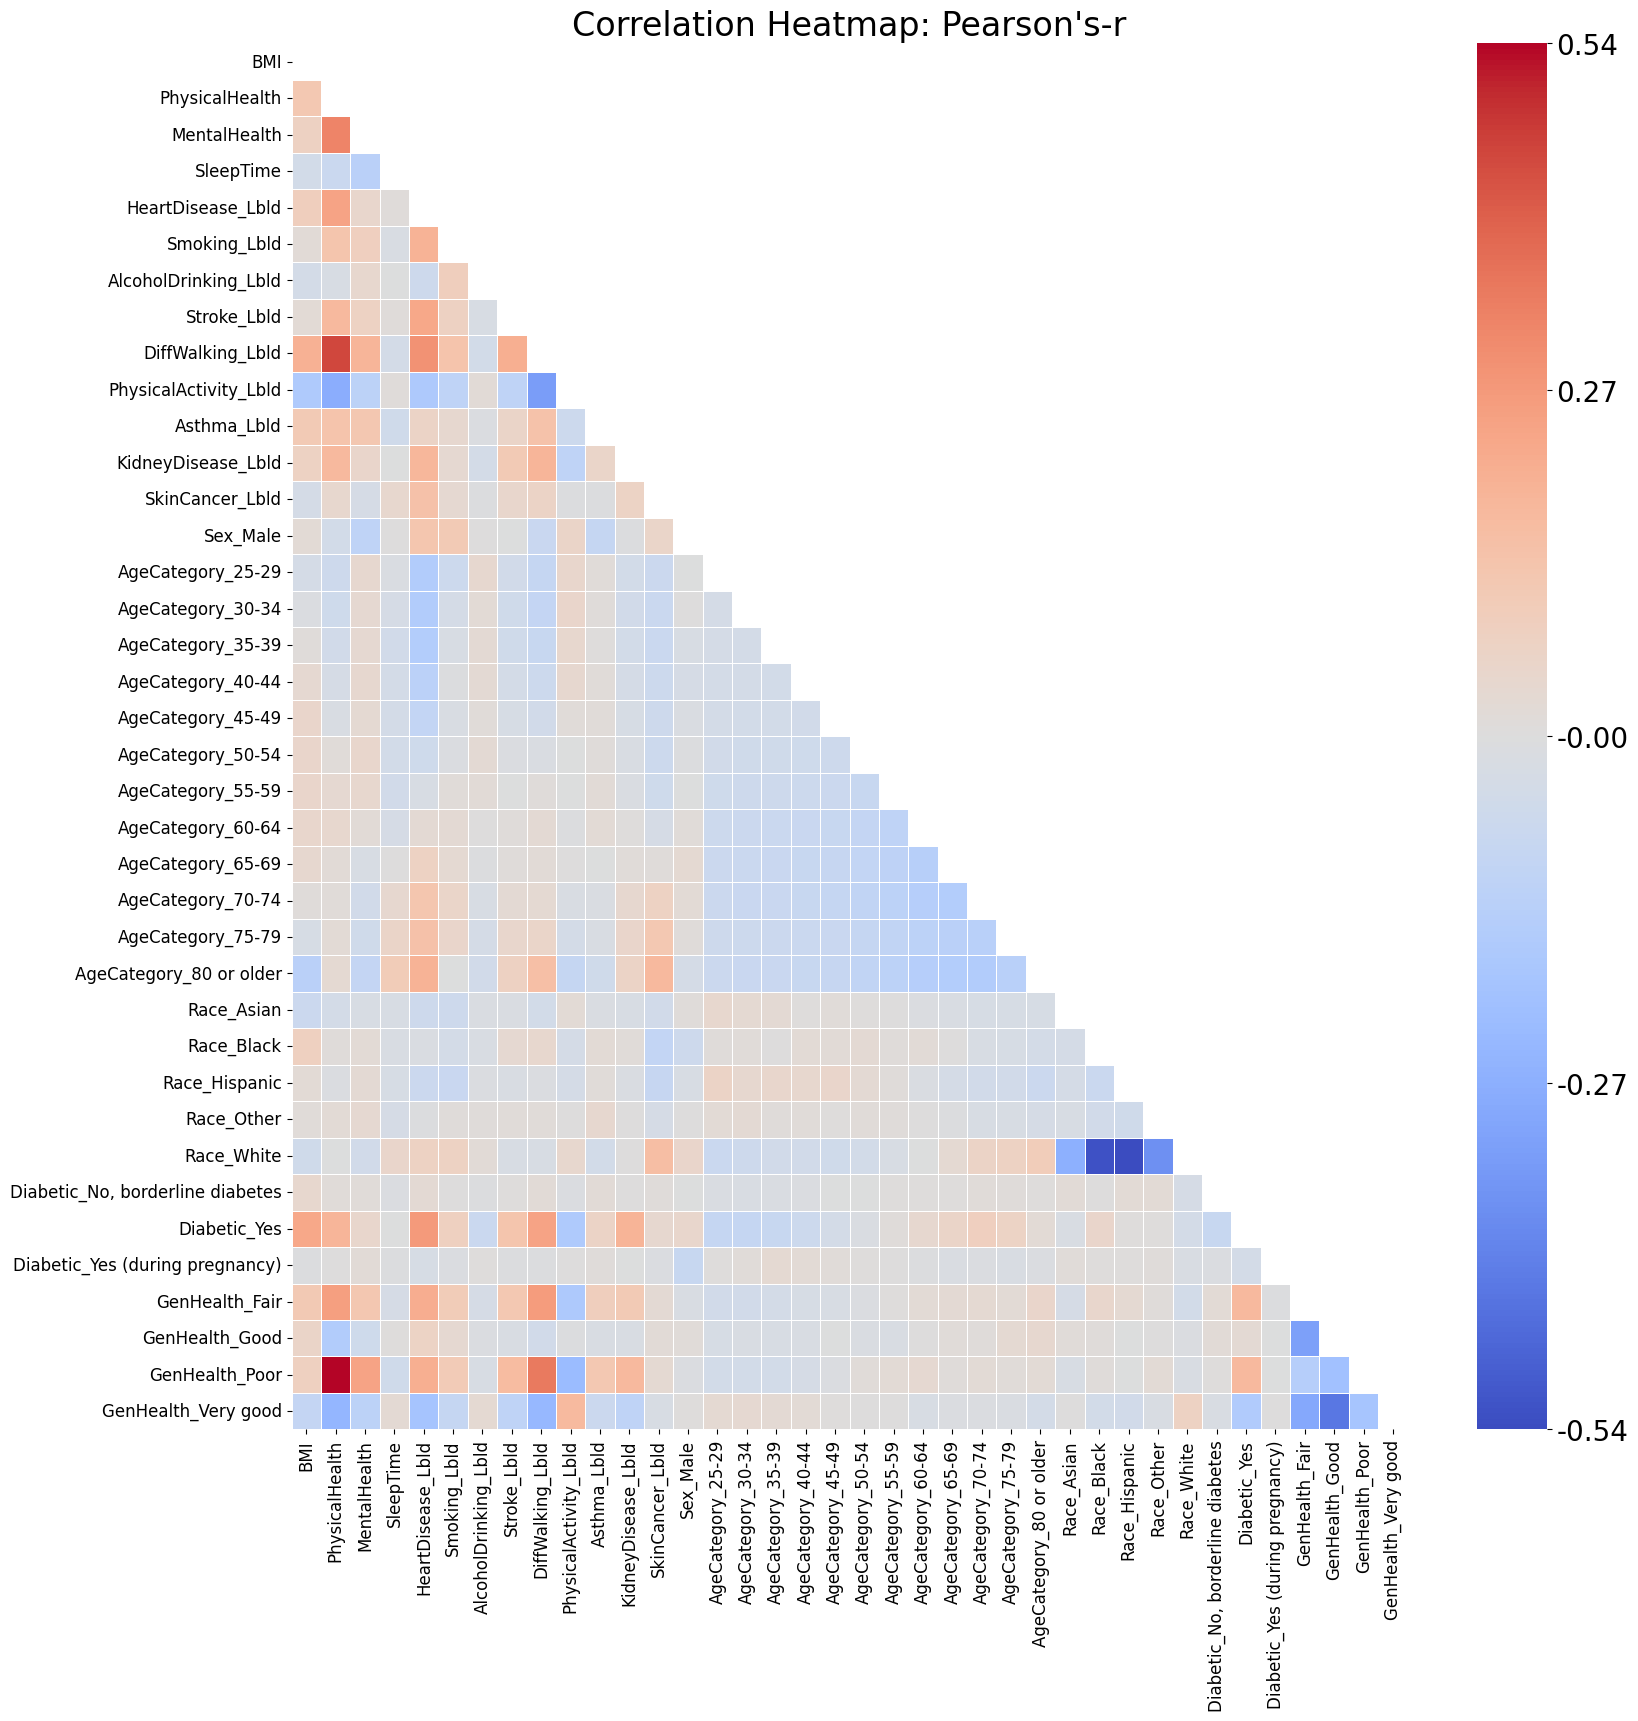

In [ ]:
# --- Correlation Matrix
hrtdisBAL_numeric = hrtdisBAL.select_dtypes(exclude=['object'])
cormat      = hrtdisBAL_numeric.corr(method='pearson')
# --- Exclude diagonal and upper triangle
mask = np.triu(np.ones_like(cormat, dtype=bool), k=0)

# --- Get min and max
vals = cormat.values.flatten()
next_max = vals[vals < 1].max()
vmin = cormat.min().min()
vmax = next_max

# --- Generating Figure
figCorr = plt.figure(figsize=(18,18))
hm = sns.heatmap(cormat,mask=mask,cmap='coolwarm',fmt='.2f',linewidths=0.5,center=0)
# --- Set colorbar ticks
cbar = hm.collections[0].colorbar
ticks = np.linspace(vmin, vmax, 5)  # includes min and max

cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t:.2f}" for t in ticks])

plt.title("Correlation Heatmap: Pearson's-r")
figCorr.savefig(f"{path}CorrelationHeatmap.png", dpi=200, bbox_inches='tight')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()
plt.close(figCorr)

In [ ]:
hrtdisBAL_numeric.head()

,BMI,PhysicalHealth,MentalHealth,SleepTime,HeartDisease_Lbld,Smoking_Lbld,AlcoholDrinking_Lbld,Stroke_Lbld,DiffWalking_Lbld,PhysicalActivity_Lbld,...,Race_Hispanic,Race_Other,Race_White,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy),GenHealth_Fair,GenHealth_Good,GenHealth_Poor,GenHealth_Very good
0,45.05,15.0,30.0,6.0,1,1,0,0,1,0,...,0,0,1,0,1,0,1,0,0,0
1,35.87,0.0,0.0,8.0,0,0,0,0,0,1,...,0,0,1,0,1,0,1,0,0,0
2,37.61,3.0,0.0,6.0,1,0,0,0,1,1,...,0,0,1,0,0,0,1,0,0,0
3,26.54,14.0,0.0,8.0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
4,27.12,0.0,0.0,8.0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,1,0,0


In [ ]:
# --- Splitting data for training, testing, and validation
y   = hrtdisBAL_numeric["HeartDisease_Lbld"]
X   = hrtdisBAL_numeric.drop(columns="HeartDisease_Lbld")
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=rs,stratify=y)

# --- Grabbing continuous features
contFEATS = [cols for cols in X.select_dtypes(include=["int64","float64"]).columns
                              if X[cols].nunique() > 2]

# --- Verifying that training samples are stratified
heart_disease_yes                   = y_train[y_train>0]
heart_disease_no                    = y_train[y_train==0]
heartdisease_ratio                  = (heart_disease_no.shape[0]) / sum(heart_disease_yes)
no_prcnt                            = round((heart_disease_no.shape[0] / y_train.shape[0])*100);
yes_prcnt                           = 100 - no_prcnt

# --- Initializing number of folds
k = 5

# --- Verifying that equal representation of "yes" and "no" entries was preserved
print("Patients that had heart disease: ",heart_disease_yes.shape[0])
print("Patients that did not have heart disease: ",heart_disease_no.shape[0])
print(f"Ratio of did not have heart disease to did have heart disease: {round(heartdisease_ratio)}:1")
print("")
print(f"No: {no_prcnt}% of total entries")
print(f"Yes: {yes_prcnt}% of total entries")

Patients that had heart disease:  19161
Patients that did not have heart disease:  19161
Ratio of did not have heart disease to did have heart disease: 1:1

No: 50% of total entries
Yes: 50% of total entries


# **Exporting Data to Group Members**

**Note:** After data export, re-import that data (when not used in current instance) in order to preserve consistency across model comparisons.

In [ ]:
# --- Learning the distribution of the continuous features in final training and applying it to test as well
scale         = StandardScaler()
X_train_LAST  = X_train.copy()
X_test_LAST   = X_test.copy()
X_train_LAST[contFEATS] = scale.fit_transform(X_train_LAST[contFEATS]) # Learning and applying the mean and standard deviation of the training data
X_test_LAST[contFEATS]  = scale.transform(X_test_LAST[contFEATS])

# --- Saving the final training and testing datasets
X_train_LAST["HeartDisease_Lbld"] = y_train.values
X_test_LAST["HeartDisease_Lbld"]  = y_test.values
X_train_LAST.to_csv(f"{path}Xtrain_scaled_final.csv", index=False)
X_test_LAST.to_csv(f"{path}Xtest_scaled_final.csv", index=False)

# --- Create and export scaled, k-folds for use by group-members.
kfold = StratifiedKFold(n_splits=k,shuffle=True,random_state=rs)

for kk, (trainIDX,validIDX) in enumerate(kfold.split(X_train,y_train),start=1):

  # --- Creating Training and validation dataset and target feature
  Xtrain_fold = X_train.iloc[trainIDX].copy().reset_index(drop=True)
  ytrain_fold = y_train.iloc[trainIDX].copy().reset_index(drop=True)
  Xvalid_fold = X_train.iloc[validIDX].copy().reset_index(drop=True)
  yvalid_fold = y_train.iloc[validIDX].copy().reset_index(drop=True)

  # --- Learning and applying distribution of continuous features to training fold and applying to validation.
  # Since each fold is seen as new data, then the distribution of the continuous features in that fold
  # needs to be learned. This prevents data leakage into the validation sets.
  kfoldScaler = StandardScaler()
  Xtrain_fold[contFEATS] = kfoldScaler.fit_transform(Xtrain_fold[contFEATS])
  Xvalid_fold[contFEATS] = kfoldScaler.transform(Xvalid_fold[contFEATS])

  # --- Concatenating target feature to scaled data and exporting
  Xtrain_foldDF = Xtrain_fold.copy()
  Xtrain_foldDF["HeartDisease_Lbld"] = ytrain_fold
  Xvalid_foldDF = Xvalid_fold.copy()
  Xvalid_foldDF["HeartDisease_Lbld"] = yvalid_fold

  Xtrain_foldDF.to_csv(f"{path}Xtrain_scaled_fold_{kk}.csv", index=False)
  Xvalid_foldDF.to_csv(f"{path}Xvalid_scaled_fold_{kk}.csv", index=False)

# **Data Import**

In [ ]:
# --- Initializing Tensors
foldTensors = []

for jj in range(1,k+1): # k+1 since it goes up to k-iterations but stops at k+1.

  # --- Importing data corresponding to jj-th fold
  trainDF = pd.read_csv(f"{path}Data/Xtrain_scaled_fold_{jj}.csv")
  validDF = pd.read_csv(f"{path}Data/Xvalid_scaled_fold_{jj}.csv")

  # --- Splitting data into model data and target feature
  ytrain = trainDF["HeartDisease_Lbld"]
  yvalid = validDF["HeartDisease_Lbld"]
  Xtrain = trainDF.drop(columns="HeartDisease_Lbld")
  Xvalid = validDF.drop(columns="HeartDisease_Lbld")

  # --- Training Tensors
  Xtrain_tensor = torch.tensor(Xtrain.values, dtype=torch.float32).to(device)
  ytrain_tensor = torch.tensor(ytrain.values, dtype=torch.float32).view(-1,1).to(device)

  # --- Validation Tensors
  Xvalid_tensor = torch.tensor(Xvalid.values, dtype=torch.float32).to(device)
  yvalid_tensor = torch.tensor(yvalid.values, dtype=torch.float32).view(-1,1).to(device)

  # --- Storing tensors corresponding to jj-th fold
  foldTensors.append({"fold": jj,"XtrainTensor": Xtrain_tensor,"ytrainTensor": ytrain_tensor,
                      "XvalidTensor": Xvalid_tensor,"yvalidTensor": yvalid_tensor})

# **Model Code -- Pytorch**



## MLP Class Definition

In [ ]:
# --- Pytorch Model Class
class HeartDiseaseMLP(torch.nn.Module):
  def __init__(self,DataDim,HiddenNeurons,OutputNeurons):
    super().__init__()
    self.model = torch.nn.Sequential(
        # --- Layer 1
        torch.nn.Linear(DataDim,HiddenNeurons),
        torch.nn.ReLU(),
        torch.nn.Dropout(0.2), # Drop X * 100% neurons randomly
        # --- Layer 2
        torch.nn.Linear(HiddenNeurons,HiddenNeurons // 2),
        torch.nn.ReLU(),
        torch.nn.Dropout(0.2),
        torch.nn.Linear(HiddenNeurons // 2,OutputNeurons),
    )
  def forward(self,x):
    return self.model(x)

## Model Hyperparameters

In [ ]:
# --- Model Hyperparameters
HiddNrns          = [50, 100, 150]
OutNrns           = 1
LrnRate           = [0.0005, 0.005, 0.05]
wghtDecay         = [0, 1e-4]                     # Adds penelty to larger weights
Epochs            = 1000
validLossThresh   = 1e-4                          # Determines early stop condition
wait              = 5                             # Parameter indicating number of epochs to improve fit before termination
results           = []

## Model Training and Validation

In [ ]:
# --- Starting simulation runtime tracking
startTime = time.perf_counter()

# --- Print Parameter
line = "-" * 57

for foldData in foldTensors:
  # --- Retrieving the fold number and corresponding tensors
  fold = foldData["fold"]
  print(line)
  print()
  print(f"Fold {fold}".center(len(line)))
  print()
  print(line)
  X_train_tensor = foldData["XtrainTensor"]
  y_train_tensor = foldData["ytrainTensor"]
  X_valid_tensor = foldData["XvalidTensor"]
  y_valid_tensor = foldData["yvalidTensor"]

  # --- Retrieving size of data for model
  dataSze = X_train_tensor.shape[1]

  # --- Loss Function
  LossFcn = torch.nn.BCEWithLogitsLoss()

  for hiddnrns in HiddNrns:
    for lrnrate in LrnRate:
      for wghtdec in wghtDecay:
        # --- Printing out the hyperparameter inputs used
        print(line)
        print(f"Number of Hidden Neurons: {hiddnrns}")
        print(f"Model Learning Rate: {lrnrate}")
        print(f"Weight Decay: {wghtdec}\n")

        # --- Initializing Model. Model also needs to be re-initialized prior to every
        # training/validation run.
        mdl = HeartDiseaseMLP(dataSze,hiddnrns,OutNrns).to(device)

        # --- Optimizer Function
        OptFcn = torch.optim.Adam(mdl.parameters(),lr=lrnrate,weight_decay=wghtdec)

        # --- Initializing early termination variables
        bestValidLoss   = float("inf")
        epochNoImprove  = 0
        bestMdl         = None

        # --- Training Loop and Validation Loss
        trainLoss       = []
        validLoss       = []
        EpochRprt       = []

        for ii in range(Epochs):
          # --- Training Step
          mdl.train()
          OptFcn.zero_grad()
          train_logits  = mdl(X_train_tensor)
          train_loss    = LossFcn(train_logits,y_train_tensor)

          train_loss.backward()
          OptFcn.step()
          mdl.eval()

          # --- Validation Step
          # Model is evaluated using the validation data. This means no update step is
          # required, hence the use of torch.no_grad().
          with torch.no_grad():
            valid_logits  = mdl(X_valid_tensor)
            valid_loss    = LossFcn(valid_logits,y_valid_tensor)

          # --- Initializing loss values
          train_loss_value = train_loss.item()
          valid_loss_value = valid_loss.item()

          # --- Prints Loss values every 20th Epoch
          if ii % 20 == 0:
            print(f"| Epoch {ii :3d} | "
              f"Train Loss: {train_loss_value:8.6f} | "
              f"Valid Loss: {valid_loss_value:8.6f}"
              )
          # --- Appending loss values and number of epochs
          trainLoss.append(train_loss_value)
          validLoss.append(valid_loss_value)
          EpochRprt.append(ii)

          # --- Early Termination
          # This works by finding setting an improved validation loss based on the difference
          # of the previous best validation loss value and a small change.
          if valid_loss_value < bestValidLoss - validLossThresh:
            bestValidLoss   = valid_loss_value
            bestMdl         = copy.deepcopy(mdl.state_dict())
            epochNoImprove  = 0
          else:
            epochNoImprove  += 1

          # This portion of the termination keeps the iterations going until it greater
          # or equal to the value of wait.
          if epochNoImprove >= wait:
            print(f"\nEarly stopping triggered at epoch {ii}\n")
            break

        # --- Restore the best model from the current training/validation run
        if bestMdl is not None:
            mdl.load_state_dict(bestMdl)

        # --- Initial Predictions with Validation Set
        mdl.eval()
        with torch.no_grad():
          valid_logits  = mdl(X_valid_tensor)
          valid_prob    = torch.sigmoid(valid_logits)

        # --- Initializing true and predicted target variable and calculating model
        # metrics for each completion of model training and validation.
        y_true    = y_valid_tensor.cpu().numpy().ravel()
        y_score   = valid_prob.cpu().numpy().ravel()

        # --- Calculating Youden's-J statistic to find best activation threshold
        # for the current model. To interpret this, the statistic is the optimal cutoff
        # value for determining whether the output is classified as either having
        # heart disease or not.

        fpr, tpr, thresholds = roc_curve(y_true, y_score)
        J = tpr - fpr
        Jidx = np.argmax(J)
        bestThresh = thresholds[Jidx]
        maxJ = J[Jidx]

        # --- Applying Youden's-J to predicted output
        y_pred = (y_score >= bestThresh).astype(float)

        accuracy  = accuracy_score(y_true,y_pred)
        precision = precision_score(y_true, y_pred,zero_division=0)
        recall    = recall_score(y_true, y_pred,zero_division=0)
        f1        = f1_score(y_true, y_pred,zero_division=0)
        roc_auc = auc(fpr, tpr)


        # --- Storing results
        results.append({"fold":fold,"HiddenNeurons":hiddnrns,"LearnRate":lrnrate, "WeightDecay":wghtdec,
                      "BestValidationLoss":bestValidLoss,"Epochs":ii + 1,"accuracy":accuracy,"precision":precision,
                      "recall":recall,"f1":f1,"trainLoss":trainLoss,"validLoss":validLoss,
                      "Epochreport":EpochRprt,"falsepos":fpr,"truepos":tpr,"threshold":thresholds,
                      "rocauc":roc_auc,"BestYoudenJ":maxJ,"BestThreshold":bestThresh})

# --- Runtime
# If the GPU resources of Google Collab Pro are utilized, then the compute time
# is snynchronized so that the training time is accurate
if torch.cuda.is_available():
  torch.cuda.synchronize()

endTime      = time.perf_counter()
trainRuntime = (endTime - startTime) / 60
print(f"\nSimulation Runtime: {trainRuntime:4.2f} minutes")

---------------------------------------------------------

                          Fold 1                         

---------------------------------------------------------
---------------------------------------------------------
Number of Hidden Neurons: 50
Model Learning Rate: 0.0005
Weight Decay: 0

| Epoch   0 | Train Loss: 0.697816 | Valid Loss: 0.696669
| Epoch  20 | Train Loss: 0.686204 | Valid Loss: 0.685208
| Epoch  40 | Train Loss: 0.670255 | Valid Loss: 0.668335
| Epoch  60 | Train Loss: 0.642230 | Valid Loss: 0.638032
| Epoch  80 | Train Loss: 0.601575 | Valid Loss: 0.594192
| Epoch 100 | Train Loss: 0.561949 | Valid Loss: 0.551671
| Epoch 120 | Train Loss: 0.539164 | Valid Loss: 0.525918
| Epoch 140 | Train Loss: 0.524369 | Valid Loss: 0.512059
| Epoch 160 | Train Loss: 0.516516 | Valid Loss: 0.504053
| Epoch 180 | Train Loss: 0.512049 | Valid Loss: 0.499251
| Epoch 200 | Train Loss: 0.508781 | Valid Loss: 0.496426
| Epoch 220 | Train Loss: 0.505965 | Valid Loss: 0.494

## Export/Import Results

In [ ]:
resultDF = pd.DataFrame(results)

In [ ]:
# --- Exporting result object.
with open(f"{path}grid_search_results_FOLDS.pkl","wb") as f:
  pickle.dump(resultDF,f)

In [ ]:
# --- Importing result  object
#with open(f"{path}grid_search_results_FOLDS.pkl", "rb") as f:
#    resultDF = pickle.load(f)

# **Grid Search Visualization of Average Metrics**

In [ ]:
# --- Retrieving the average metrics and median threshold and Youden-J across all folds
avgMetrics = resultDF.groupby(["HiddenNeurons","LearnRate","WeightDecay"],as_index=False).agg(
    {"accuracy": "mean","precision": "mean","recall": "mean","f1": "mean","rocauc": "mean",
        "BestThreshold": "median","BestYoudenJ": "median"})

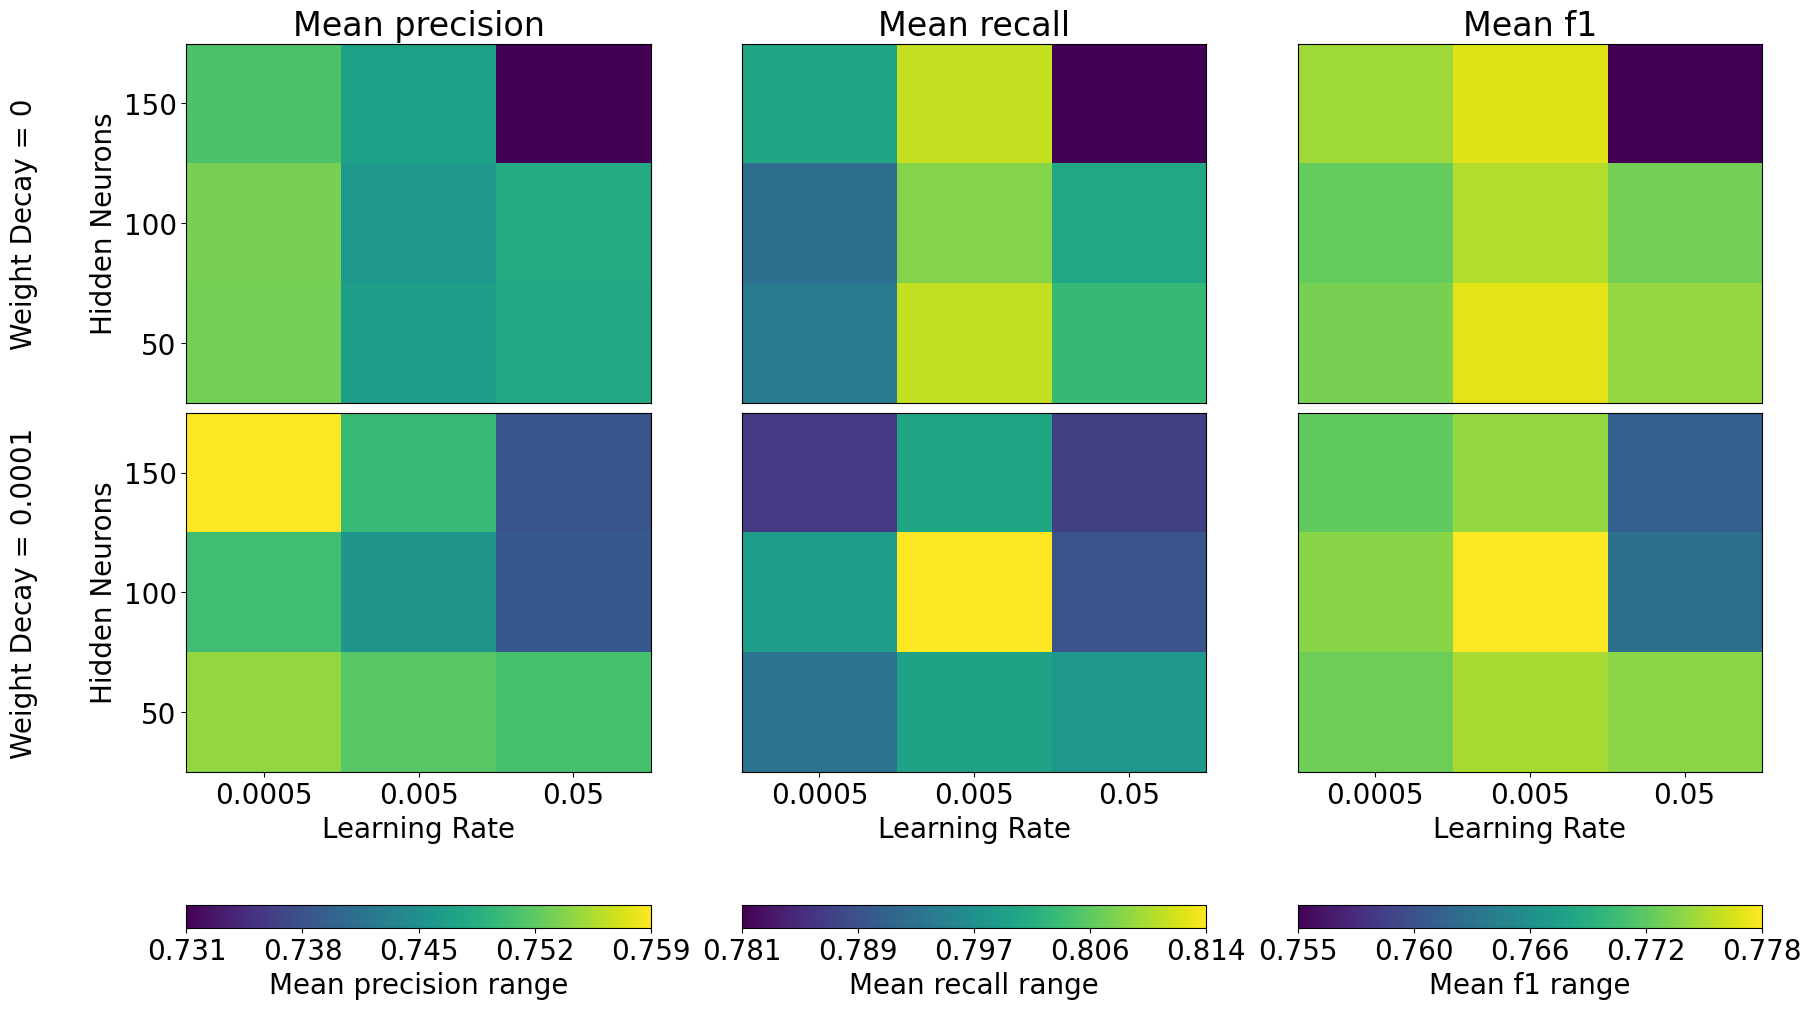

In [ ]:
# --- Visual of Average Model Performance across k-validations
plt.rcParams["font.size"] = 20

metrics = ["precision", "recall", "f1"]

fig, axs = plt.subplots(
    len(wghtDecay), len(metrics),
    figsize=(6 * len(metrics), 5 * len(wghtDecay)),squeeze=False,constrained_layout=True)

# --- Plotting loops
for jj, metric in enumerate(metrics):

    metricMin = avgMetrics[metric].min()
    metricMax = avgMetrics[metric].max()

    for ii, wd in enumerate(wghtDecay):

        ax = axs[ii, jj]

        sub_df = avgMetrics[avgMetrics["WeightDecay"] == wd]
        grid = sub_df.pivot(index="HiddenNeurons",columns="LearnRate",
            values=metric)

        im = ax.imshow(grid.values,aspect="auto",origin="lower",
            vmin=metricMin,vmax=metricMax)

        # --- Column titles: metrics
        if ii == 0:
            ax.set_title("Mean " + metric)

        # --- Left-side row labels: weight decay
        if jj == 0:
          ax.set_ylabel("Hidden Neurons")
          ax.set_yticks(range(len(grid.index)))
          ax.set_yticklabels(grid.index)

          # --- Add weight decay label to the LEFT of subplot
          ax.text(-0.35, 0.5,f"Weight Decay = {wd}",transform=ax.transAxes,rotation=90,
                  va='center',ha='center',fontsize=20)
        else:
            ax.set_yticks([])

        # --- Bottom x-labels only
        if ii == len(wghtDecay) - 1:
            ax.set_xlabel("Learning Rate")
            ax.set_xticks(range(len(grid.columns)))
            ax.set_xticklabels(grid.columns)
        else:
            ax.set_xticks([])

    # --- One horizontal colorbar per metric column
    cbar = fig.colorbar(im,ax=axs[:, jj],orientation="horizontal",
        fraction=0.05,pad=0.08)

    ticks = np.linspace(metricMin, metricMax, 5)
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f"{t:.3f}" for t in ticks])
    cbar.set_label("Mean "+metric+" range")

# --- Showing and exporting figure
fig.savefig(f"{path}GridSearchResults.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# **Model Performance Corresponding to Maximal Average Recall**

## Outputting all model performance figures before final training and testing

In [ ]:
# --- Grabbing data corresponding to maximal average recall
maxAvgRec_Pre = avgMetrics.loc[avgMetrics["recall"].idxmax()]

# --- Grabbing data across all folds that corresponds to hyperparameters maximizing
# average recall
bestResults_Pre = resultDF[
(resultDF["HiddenNeurons"] == maxAvgRec_Pre["HiddenNeurons"]) &
(resultDF["LearnRate"] == maxAvgRec_Pre["LearnRate"]) &
(resultDF["WeightDecay"] == maxAvgRec_Pre["WeightDecay"])]

Mean Accuracy Across Folds: 0.7681
Accuracy Standard Deviation Across Folds: 0.0049



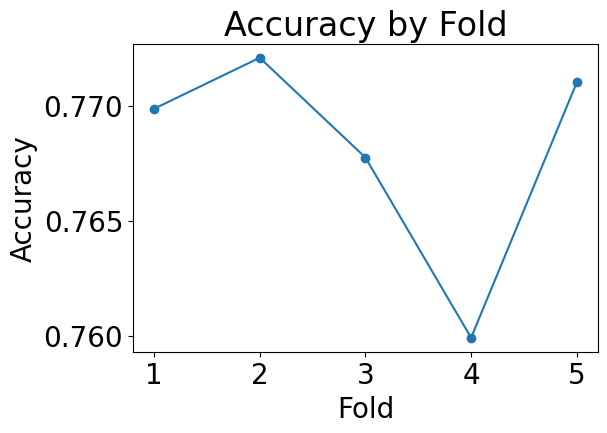

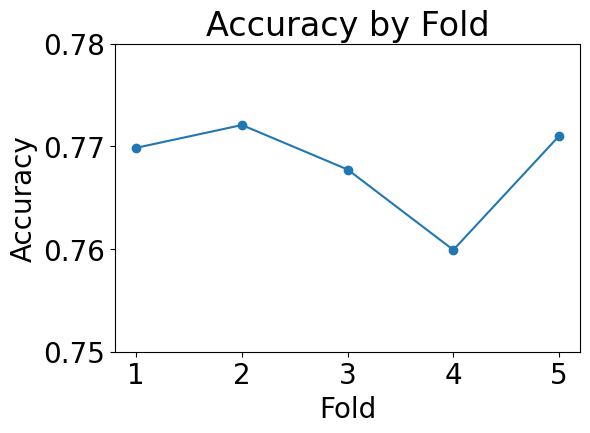

In [ ]:
# --- Ouputting accuracy metrics across folds for performance check
meanACC = bestResults_Pre["accuracy"].mean()
stdACC = bestResults_Pre["accuracy"].std()

print(f"Mean Accuracy Across Folds: {meanACC:5.4f}")
print(f"Accuracy Standard Deviation Across Folds: {stdACC:5.4f}\n")

fig_ACC_Pre = plt.figure(figsize=(6,4))
plt.plot(bestResults_Pre["fold"], bestResults_Pre["accuracy"], marker="o")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Accuracy by Fold")
plt.xticks(bestResults_Pre["fold"])
fig_ACC_Pre.savefig(f"{path}AccuracyByFold_Pre.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig_ACC_Pre)

fig_ACC_Pre = plt.figure(figsize=(6,4))
plt.plot(bestResults_Pre["fold"], bestResults_Pre["accuracy"], marker="o")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.ylim(0.75, 0.78)
plt.title("Accuracy by Fold")
plt.xticks(bestResults_Pre["fold"])
fig_ACC_Pre.savefig(f"{path}AccuracyByFold_Pre_ZoomedOut.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig_ACC_Pre)

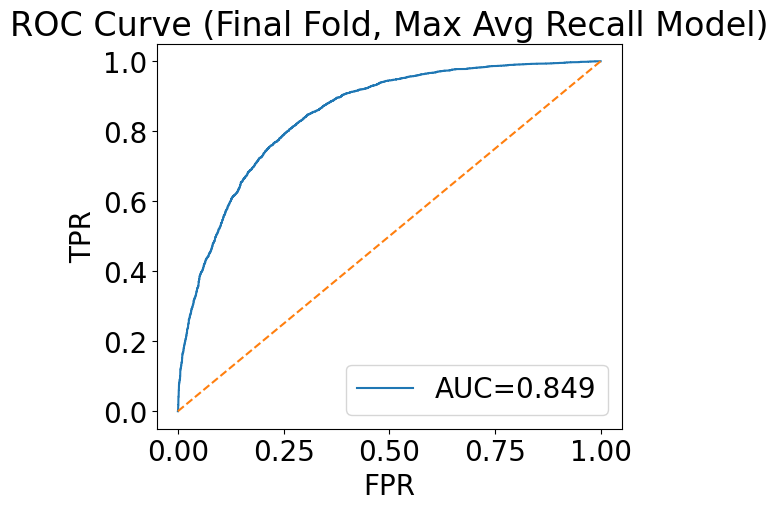

In [ ]:
# --- Outputting ROC curve of final fold
finalFold = bestResults_Pre["fold"].max()
finalRow = bestResults_Pre[bestResults_Pre["fold"] == finalFold].iloc[0]

fig_ROC_Pre = plt.figure(figsize=(6, 5))
plt.plot(finalRow["falsepos"], finalRow["truepos"],
         label=f"AUC={finalRow['rocauc']:.3f}")
plt.plot([0,1],[0,1],'--')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Curve (Final Fold, Max Avg Recall Model)")
plt.legend()
fig_ROC_Pre.savefig(f"{path}ROC_FinalFold_Pre.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig_ROC_Pre)

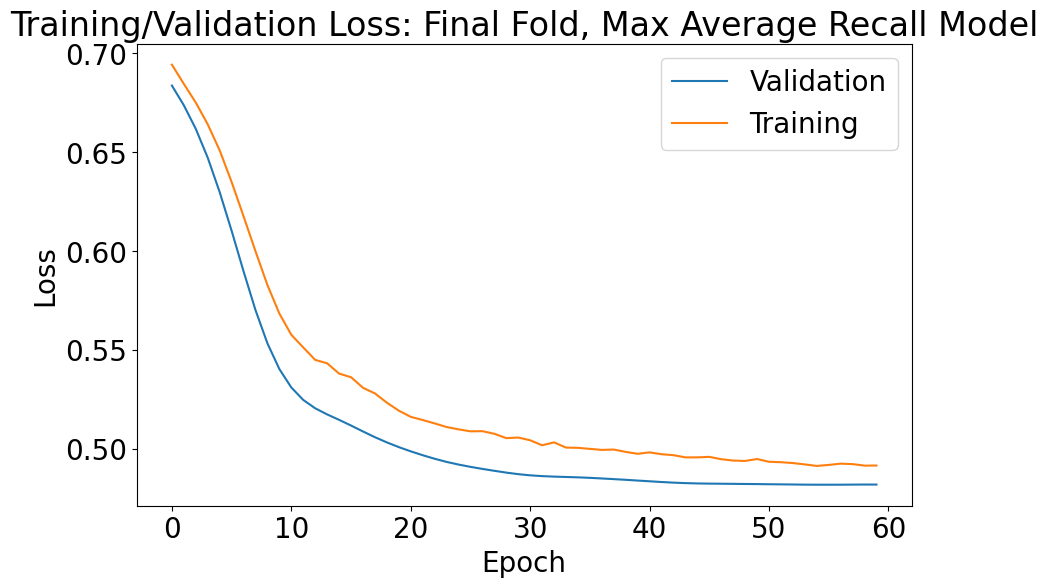

In [ ]:
# --- Outputting Loss curves of final fold. While not necessary for classification,
# it is still a good supporting figurre to have.
plt.figure(figsize=(10, 6))
plt.plot(finalRow["Epochreport"],finalRow["validLoss"])
plt.plot(finalRow["Epochreport"],finalRow["trainLoss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training/Validation Loss: Final Fold, Max Average Recall Model")
plt.legend(["Validation","Training"])
plt.show()

# **Final Training and Validation**

In [ ]:
# --- Importing Final Training and Test Data
finaltrainDF = pd.read_csv(f"{path}Data/Xtrain_scaled_final.csv")
finaltestDF = pd.read_csv(f"{path}Data/Xtest_scaled_final.csv")

# --- Splitting data into model data and target feature
ytrain_final = finaltrainDF["HeartDisease_Lbld"]
ytest_final = finaltestDF["HeartDisease_Lbld"]
Xtrain_final = finaltrainDF.drop(columns="HeartDisease_Lbld")
Xtest_final = finaltestDF.drop(columns="HeartDisease_Lbld")

# --- Training Tensors
Xtrain_tensor_final = torch.tensor(Xtrain_final.values, dtype=torch.float32).to(device)
ytrain_tensor_final = torch.tensor(ytrain_final.values, dtype=torch.float32).view(-1,1).to(device)

# --- Test Tensors
Xtest_tensor_final = torch.tensor(Xtest_final.values, dtype=torch.float32).to(device)
ytest_tensor_final = torch.tensor(ytest_final.values, dtype=torch.float32).view(-1,1).to(device)

# --- Retrieving model hyperparameters corresponding to best mean recall
best_HiddnNrns = int(maxAvgRec_Pre["HiddenNeurons"])
best_lrnrate   = maxAvgRec_Pre["LearnRate"]
best_wghtdecay = maxAvgRec_Pre["WeightDecay"]

# --- AVG number of Epochs corresponding to the maximized, average recall
best_epochs    = int(round(bestResults_Pre["Epochs"].min()))

# --- Retrieving median Youden's-J and corresponding activation threshold
# that maximizes recall
bestJ          = maxAvgRec_Pre["BestYoudenJ"]
bestThreshold  = maxAvgRec_Pre["BestThreshold"]

# --- Initializing Model. Model also needs to be re-initialized prior to every
# training/validation run.
dataSze = Xtrain_tensor_final.shape[1]
mdl_final = HeartDiseaseMLP(dataSze,best_HiddnNrns,OutNrns).to(device)

# --- Optimizer Function
OptFcn = torch.optim.Adam(mdl_final.parameters(),lr=best_lrnrate,weight_decay=best_wghtdecay)

# --- Loss Function
LossFcn = torch.nn.BCEWithLogitsLoss()

In [ ]:
# --- NOTE: Unlike during k-folds, early termination is not required since we are only
# training across the entire preocessed dataset. The number of epochs is based on the
# number of epochs that elicited the best average recall

# --- Final Training Loop
trainLoss  = []
EpochRprt  = []

# --- Starting simulation runtime tracking
startTime = time.perf_counter()

print(line)
print("Final Model Training".center(len(line)))
for ii in range(best_epochs):
  # --- Training Step
  mdl_final.train()
  OptFcn.zero_grad()
  train_logits  = mdl_final(Xtrain_tensor_final)
  train_loss    = LossFcn(train_logits,ytrain_tensor_final)

  # --- Update Step
  train_loss.backward()
  OptFcn.step()

  # --- Initializing loss values
  train_loss_value = train_loss.item()

  # --- Prints Loss values every 20th Epoch
  if ii % 10 == 0:
    print(f"| Epoch {ii :3d} | "f"Train Loss: {train_loss_value:8.6f} | ")

  # --- Appending loss values and number of epochs
  trainLoss.append(train_loss_value)
  EpochRprt.append(ii)

# --- Outputting final training runtime
if torch.cuda.is_available():
  torch.cuda.synchronize()

endTime      = time.perf_counter()
trainRuntime = (endTime - startTime) / 60
print(line)
print(f"\nSimulation Runtime: {trainRuntime:4.2f} minutes")

---------------------------------------------------------
                   Final Model Training                  
| Epoch   0 | Train Loss: 0.698759 | 
| Epoch  20 | Train Loss: 0.516350 | 
| Epoch  40 | Train Loss: 0.496738 | 


## Final Model Export

In [ ]:
# --- Export model trained on final data
with open(f"{path}model_fully_trained.pkl","wb") as f:
  pickle.dump(mdl_final,f)

In [ ]:
# --- Final Predictions with Test Set
mdl_final.eval()
with torch.no_grad():
  test_logits = mdl_final(Xtest_tensor_final)
  test_prob   = torch.sigmoid(test_logits)
  test_loss   = LossFcn(test_logits,ytest_tensor_final)

# --- Initializing true and predicted target variable and calculating model
# metrics for each completion of model training and validation.
y_true_final  = ytest_tensor_final.cpu().numpy().ravel()
y_score_final = test_prob.cpu().numpy().ravel()

# --- Storing Test Loss
test_loss_value = test_loss.item()

# --- Calculating roc/auc metrics
fpr_final, tpr_final, thresholds_final = roc_curve(y_true_final, y_score_final)

# --- Applying the activation threshold corresponding to the best Youden's J
# statistic which optimizes decision threshold
y_pred_final = (y_score_final >= bestThreshold).astype(float)

accuracy_final  = accuracy_score(y_true_final,y_pred_final)
precision_final = precision_score(y_true_final, y_pred_final,zero_division=0)
recall_final    = recall_score(y_true_final, y_pred_final,zero_division=0)
f1_final        = f1_score(y_true_final, y_pred_final,zero_division=0)
roc_auc_final   = auc(fpr_final, tpr_final)

# Finalized Model Performance

In [ ]:
# --- Printing Model Performance Metrics
print()
print("Final Model Performance Metrics".center(len(line)))
print(line)
#print(f"Model Test Loss: {test_loss_value:6.4f}\n")
print(f"Overall Model Accuracy: {accuracy_final:6.4f}\n")
print(f"Overall Model Recall: {recall_final:6.4f}\n")
print(f"Overall Model Precision: {precision_final:6.4f}\n")
print(f"Overall Model f1-score: {f1_final:6.4f}\n")
print(f"Test ROC-AUC: {roc_auc_final:6.4f}\n")
print(line)
# --- Classification Report
print(classification_report(y_true_final, y_pred_final, target_names=["No Heart Disease", "Had Heart Disease"]))


             Final Model Performance Metrics             
---------------------------------------------------------
Overall Model Accuracy: 0.7656

Overall Model Recall: 0.8019

Overall Model Precision: 0.7476

Overall Model f1-score: 0.7738

Test ROC-AUC: 0.8414

---------------------------------------------------------
                   precision    recall  f1-score   support

 No Heart Disease       0.79      0.73      0.76      8212
Had Heart Disease       0.75      0.80      0.77      8212

         accuracy                           0.77     16424
        macro avg       0.77      0.77      0.77     16424
     weighted avg       0.77      0.77      0.77     16424



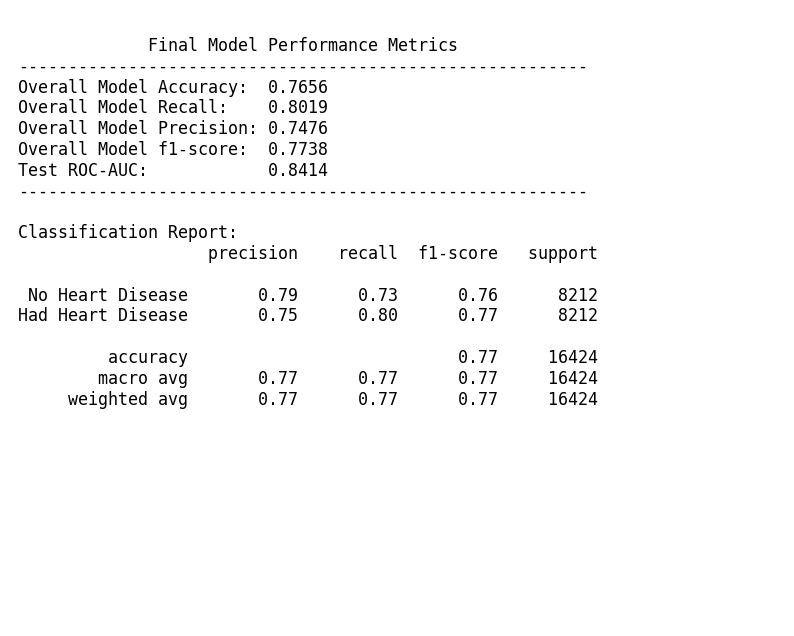

In [ ]:
# --- Output classification report and model metrics in a png file
report = classification_report(y_true_final,y_pred_final,
    target_names=["No Heart Disease", "Had Heart Disease"],zero_division=0)

text = ("\n" + "Final Model Performance Metrics".center(len(line)) + "\n"
    + line + "\n" + f"Overall Model Accuracy:  {accuracy_final:6.4f}\n"
    + f"Overall Model Recall:    {recall_final:6.4f}\n"
    + f"Overall Model Precision: {precision_final:6.4f}\n"
    + f"Overall Model f1-score:  {f1_final:6.4f}\n"
    + f"Test ROC-AUC:            {roc_auc_final:6.4f}\n" + line + "\n"
    + "\nClassification Report:\n" + report)

# --- Render the text to figure
fig = plt.figure(figsize=(10, 8))
plt.text(0.01, 0.99, text, fontsize=12, va='top', family='monospace')
plt.axis('off')
# --- Save
fig.savefig(f"{path}Final_Model_Report.png", dpi=300, bbox_inches='tight')

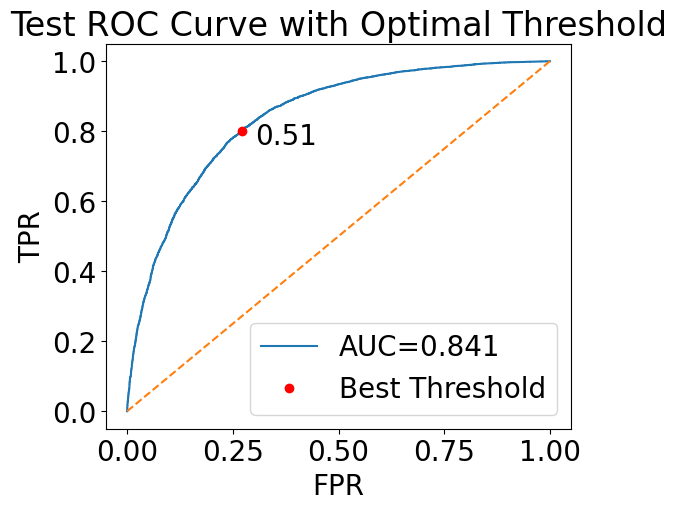

In [ ]:
# --- Retrieving index corresponding best Youden's-J to plot best false positive
# and true positive rates
idx = np.argmin(np.abs(thresholds_final - bestThreshold))
fpr_point = fpr_final[idx]
tpr_point = tpr_final[idx]

# --- Testing ROC Curve
fig_ROC_Test = plt.figure(figsize=(6, 5))
plt.plot(fpr_final, tpr_final,label=f"AUC={roc_auc_final:.3f}")
plt.plot(fpr_point, tpr_point,'ro',label="Best Threshold")
plt.plot([0,1],[0,1],'--')
plt.annotate(f"{bestThreshold:.2f}",(fpr_point, tpr_point),
    xytext=(10,-10),textcoords='offset points')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Test ROC Curve with Optimal Threshold")
plt.legend()
fig_ROC_Test.savefig(f"{path}ROC_Test.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig_ROC_Test)

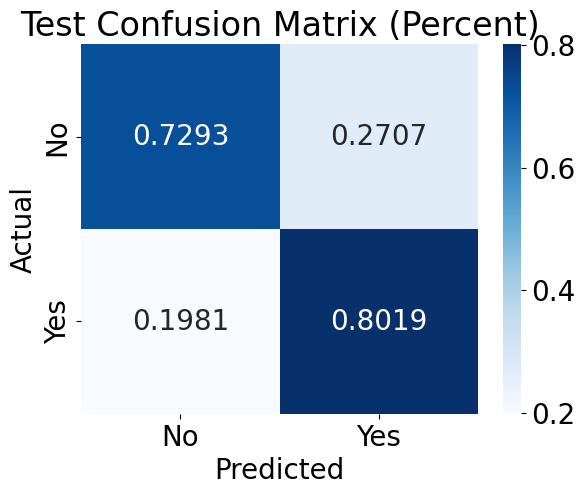

In [ ]:
# --- Confusion Matrix
cm          = confusion_matrix(y_true_final, y_pred_final)
cm_percent  = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig_ConfMat_Test = plt.figure()
sns.heatmap(cm_percent, annot=True, fmt=".4f", cmap="Blues",
            xticklabels=["No", "Yes"],yticklabels=["No", "Yes"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test Confusion Matrix (Percent)")
fig_ConfMat_Test.savefig(f"{path}ConfusionMatrix_Test.png", dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig_ConfMat_Test)